# 01 · Preprocessing — Lin 2020 PDAC (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed,
remove detached islands, and split the manifold into its transcriptional compartments.
Lin et al. 2020 is a 10x pancreatic ductal adenocarcinoma (PDAC) atlas; its malignant
compartment (`cell_type == 'Malignant'`, the publication's call) is a continuous ductal
body carrying a somitogenesis→neural-crest developmental gradient. Whether that axis is
confined to one lobe (Kürten 2021, scope) or spans the whole manifold (Bischoff / Sun /
Lee / Zhou 2020, keep all) is **derived in 02 from the signature geography + a cell-cycle
confound test**, not assumed here; both compartments are carried forward. Every tunable
choice is *derived from this dataset* (C1), *shown in the notebook* (C2), with its
structural premise checked (C3). Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Lin2020_Pancreas | category: Pancreas


### Load malignant compartment
Lin et al. supply a per-cell `cell_type` annotation in which **Malignant** is an explicit
label (the publication's epithelial ductal-carcinoma call); the loader exposes it as
`celltype`, so the malignancy call here is `celltype == 'Malignant'`, taken directly (per
protocol: use the publication's calls). The matrix is raw UMI counts, so the loader
`normalize_total` + `log1p` transforms it.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Lin2020_Pancreas
Done.
full atlas: (14926, 22217)
malignant: (10993, 22217) | samples: 16
expression: X max 7.61 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding
Sort per-sample malignant counts and cut at the largest **multiplicative** cliff — the
natural separatrix between tumour-bearing samples and low-count spillover. Unlike the
degenerate Steele 2020 case (largest ratio at the top of the distribution), here the cliff
sits at the **bottom**: 76→37 cells (ratio 2.05), a genuine spillover gap. The
clean-count-gap premise (C3) **is met**, so the derived threshold is the geometric mean
across that gap (53), retaining 15/16 samples. This is C1-derived, not the inherited
≥100 floor (which would needlessly drop three real samples of 76–191 cells).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f}) at rank {gap} of {len(vals)}')
FLOOR = 100
if gap == 0:
    print(f'gap at top of distribution (degenerate) -> fall back to >= {FLOOR}-cell floor')
    thresh = FLOOR
else:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'derived threshold (geometric mean across the spillover gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min kept = {int(n[keep].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [2767 2327 1336  844  720  696  426  410  337  336  214  191  157  119
   76   37]
largest multiplicative gap: 76 -> 37 (ratio 2.05) at rank 14 of 16
derived threshold (geometric mean across the spillover gap) = 53
kept 15/16 samples (min kept = 76) -> 10956 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction + iLISI sweep (lower same-sample
fraction / higher iLISI = better mixing): take the theta past which mixing plateaus. PDAC
malignant cells are strongly patient-specific (distinct CNVs), so the strongest theta is
chosen once mixing has plateaued. PC count (20) and UMAP spread (1.3) follow the 10x
precedents at comparable cell counts (Kürten / Sun / Lee / Steele / Zhou).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
sweep = {}; ils = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
    ils[th]   = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
print('iLISI median (of %d samples)   | pre-Harmony %.2f' % (adata.obs['sample'].nunique(), il_pre),
      '| sweep', {k: round(v,2) for k,v in ils.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 508 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 508
same-sample neighbour fraction | pre-Harmony 0.939 | sweep {2: 0.583, 5: 0.454, 10: 0.452}
iLISI median (of 15 samples)   | pre-Harmony 1.00 | sweep {2: np.float64(2.26), 5: np.float64(4.07), 10: np.float64(4.16)}
selected theta = 10 (mixing plateaus by theta=5; strongest integration without collapse)


2026-08-01 17:40:53,320 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-01 17:40:54,860 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-01 17:40:54,930 - harmonypy - INFO - Iteration 1 of 30
2026-08-01 17:40:57,378 - harmonypy - INFO - Iteration 2 of 30
2026-08-01 17:40:59,799 - harmonypy - INFO - Iteration 3 of 30
2026-08-01 17:41:01,984 - harmonypy - INFO - Converged after 3 iterations
2026-08-01 17:41:02,679 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-01 17:41:03,924 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-01 17:41:03,965 - harmonypy - INFO - Iteration 1 of 30
2026-08-01 17:41:06,312 - harmonypy - INFO - Iteration 2 of 30
2026-08-01 17:41:08,641 - harmonypy - INFO - Iteration 3 of 30
2026-08-01 17:41:10,994 - harmonypy - INFO - Iteration 4 of 30
2026-08-01 17:41:13,090 - harmonypy - INFO - Iteration 5 of 30
2026-08-01 17:41:15,285 - harmonypy - INFO - Iteration 6 of 

### Remove detached islands — characterise before deleting (C3/C4)
Build a radius graph on the UMAP (6× median nearest-neighbour distance) and take connected
components. Here the largest detached component is **substantial (652 cells across 2 components, ~6%)**, not a
speck — the calibration audit flags exactly this as the case where the rule can delete a
real second lineage, so the "keep-largest-component" premise (C3) is **checked, not
assumed**: the island is profiled biologically before removal. It proves to be a
**multi-sample** (14 samples contribute), **higher-cycling** (0.27 vs 0.13) compartment
with **flat developmental means** (Gast/pSom/Crest ≈ 0) and no coherent lineage markers
(HLA-DMA, MSN, LUM, SOCS3) — a low-signal detached stress compartment, not a developmental
arm. Removal is therefore justified and the continuous developmental body is retained.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
adata.obs['island'] = np.where(lab==main, 'main', 'island')
print('component sizes:', pd.Series(lab).value_counts().values[:5])
print('detached:', int((lab!=main).sum()), 'cells in', ncomp-1, 'island(s)')

# characterise the island before deleting (score developmental modules for the check)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
isl = adata.obs['island']=='island'
print('island: %d samples contribute' % adata.obs.loc[isl,'sample'].nunique(),
      '| cycling %.2f (main %.2f)' % (adata.obs.loc[isl,'cycling'].mean(), adata.obs.loc[~isl,'cycling'].mean()))
print('island module means:', {m: round(adata.obs.loc[isl,m].mean(),3) for m in ['Gast','pSom','Crest']},
      '| main:', {m: round(adata.obs.loc[~isl,m].mean(),3) for m in ['Gast','pSom','Crest']})
print('-> flat developmental means, multi-sample, higher-cycling: detached stress compartment, not a lineage. Remove.')
adata = adata[adata.obs['island']=='main'].copy()
print('after island removal:', adata.shape[0], 'cells on one connected component')

component sizes: [10304   651     1]
detached: 652 cells in 2 island(s)
island: 14 samples contribute | cycling 0.27 (main 0.13)
island module means: {'Gast': np.float64(-0.011), 'pSom': np.float64(-0.017), 'Crest': np.float64(0.002)} | main: {'Gast': np.float64(-0.008), 'pSom': np.float64(0.046), 'Crest': np.float64(-0.006)}
-> flat developmental means, multi-sample, higher-cycling: detached stress compartment, not a lineage. Remove.
after island removal: 10304 cells on one connected component


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers the manifold's two lobes. **Unlike Steele 2020
(a transcriptional split) and like Zhou 2020, the split here is driven by cell cycle**: the
minor lobe's top markers are proliferation genes (DTYMK, UBE2C, STMN1, TOP2A-family, PTTG1)
and it is 26% cycling, while the dominant lobe is ribosomal / non-cycling (4%). We label the
lobes by biology: **Cycling** (proliferation) vs **Ductal-body** (non-cycling bulk). Whether
the developmental axis is confounded by this proliferation split — the Kürten fork — is
tested rigorously in 02; both lobes are carried forward here.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
sc.tl.rank_genes_groups(adata, 'lobe', method='wilcoxon')
for lb in adata.obs['lobe'].cat.categories:
    print(f'lobe {lb} top markers:', [adata.uns['rank_genes_groups']['names'][lb][i] for i in range(8)])
# label by cycling fraction: higher = Cycling (proliferation), other = Ductal-body
cf = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
cyc_lobe = cf.idxmax()
lab_map = {l: ('Cycling' if l==cyc_lobe else 'Ductal-body') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 6146, '0': 4158}
cycling fraction per lobe: {'0': 0.263, '1': 0.041}
lobe 0 top markers: ['DTYMK', 'UBE2S', 'SNRNP25', 'PSMD14', 'KIAA0101', 'SMC4', 'STMN1', 'HNRNPAB']
lobe 1 top markers: ['RPS29', 'RPL22', 'RPL36', 'RPL31', 'UBA52', 'SERF2', 'PPDPF', 'RPL24']
compartments: {'Ductal-body': 6146, 'Cycling': 4158}


### House orientation — one consistent layout for every UMAP (binding)
The developmental axis is **diagonal** in the raw joint embedding, so all trajectory panels
are shown after a single **rigid rotation** to the house horizontal layout
(distance-preserving — *not* a re-embedding, which would fabricate folds in an anisotropic
compartment). The orientation is derived **once here**, stored as `X_umap_lin`, and re-used
unchanged by 02/03/04 so every deliverable UMAP shares one orientation (binding). Two
ingredients: (i) rotation angle = the manifold's **axis of maximal variance**; (ii) the sign
places the **developmental origin on the left** so pseudotime runs left→right once fit in 02.
Following Steele 2020 (and unlike Zhou 2020, whose cycling pole set the sign): PDAC here has
cell cycle partly aligned with the axis, so the sign is set directly from the
developmental-module geography — the **somitogenesis-high / neural-crest-low** pole (origin)
is placed on the left.

In [8]:
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,0] - S[:,1]        # pSom-high / Crest-low = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()                     # origin pole -> left (negative x)
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'somitogenesis-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 2.53
house orientation: rigid rotation +94.0deg (distances preserved), somitogenesis-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made
on the **regenerated embedding itself** plus a per-neighbourhood metric (iLISI across the
theta sweep), not a scalar alone: samples intermix strongly (iLISI 1.0→4.1 of 15 samples),
and after removing the one justified detached island the malignant cells form a single
connected component. **Gate 1 = GO.** The deliverable `samples.pdf` shows the intermixing.

In [9]:
n_samp = adata.obs['sample'].nunique()
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (single connected component after island removal);')
print('both compartments (Ductal-body / Cycling) contain multiple samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.11 of 15 samples
15 samples share one continuous manifold (single connected component after island removal);
both compartments (Ductal-body / Cycling) contain multiple samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


### Save processed data
Coerce mixed-type object metadata to numeric where possible (else string) so the manifold is
h5ad-serializable; analysis-relevant columns are preserved.

In [10]:
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        keep_num = s.notna().sum() > 0 and conv.notna().sum() >= 0.9*s.notna().sum()
        adata.obs[col] = conv if keep_num else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (10304, 21706)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)` horizontal strip, `size=30`) matching every other panel.
Colour = sample: intermixing across the strip is the Gate-1 evidence, shown on the house
orientation (`X_umap_lin`) so this panel shares one orientation with 02/03/04.

saved samples.pdf | cells: 10304


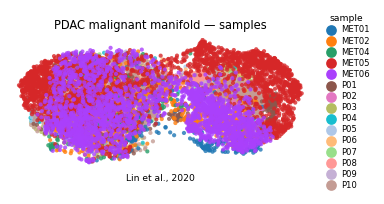

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('PDAC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Lin et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])